In [ ]:
!pip install scikit-learn rapidfuzz joblib matplotlib seaborn pandas \
             pytesseract opencv-python-headless Pillow --quiet

import subprocess
result = subprocess.run(['which', 'tesseract'], capture_output=True, text=True)
if not result.stdout.strip():
    subprocess.run(['apt-get', 'install', '-y', '-q',
                    'tesseract-ocr', 'tesseract-ocr-eng',
                    'libsm6', 'libxext6'], check=True)
else:
    print(f"Tesseract found: {result.stdout.strip()}")

Tesseract found: /usr/bin/tesseract


In [ ]:
import pandas as pd
import numpy as np
import json, os, re, joblib, warnings
warnings.filterwarnings('ignore')

import cv2
import pytesseract
from PIL import Image, ImageEnhance, ImageFilter

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from collections import Counter, OrderedDict
from rapidfuzz import process, fuzz
import matplotlib.pyplot as plt
import seaborn as sns

VALID_LABELS   = ['Green', 'Yellow', 'Orange', 'Red']
EMOJI          = {'Green':'🟢', 'Yellow':'🟡', 'Orange':'🟠', 'Red':'🔴'}
COLORS         = {'Green':'#22c55e', 'Yellow':'#eab308', 'Orange':'#f97316', 'Red':'#ef4444'}
VERDICT_WEIGHT = {'Green': 0, 'Yellow': 1, 'Orange': 2, 'Red': 3}

In [ ]:
CSV_PATH = "/content/ingredient_dataset_with_synonyms (1).csv"

df = pd.read_csv(CSV_PATH)
df.columns = [c.strip().lower() for c in df.columns]

df['ingredient_name'] = df['ingredient_name'].str.strip().str.lower()
df['label']           = df['label'].str.strip().str.capitalize()
df['category']        = df['category'].str.strip()
df['e_number']        = df['e_number'].fillna('').str.strip()

if 'synonyms_india' not in df.columns:
    df['synonyms_india'] = ''
    print("ℹ️  No synonyms_india column — starting with empty synonyms.")
else:
    df['synonyms_india'] = df['synonyms_india'].fillna('')

bad = df[~df['label'].isin(VALID_LABELS)]
if len(bad):
    print(f"⚠️  {len(bad)} rows with invalid labels dropped")
    df = df[df['label'].isin(VALID_LABELS)].reset_index(drop=True)

print(f" Loaded {len(df)} ingredients")
print(f"   With Indian synonyms : {(df['synonyms_india'] != '').sum()}")
print(f"   Without synonyms     : {(df['synonyms_india'] == '').sum()}")
print()
for lbl in VALID_LABELS:
    n = df['label'].value_counts().get(lbl, 0)
    print(f"  {EMOJI[lbl]} {lbl:<8} {n:>4}  {'█' * (n // 5)}")
print()
print(df.head(6).to_string(index=False))


 Loaded 541 ingredients
   With Indian synonyms : 340
   Without synonyms     : 201

  🟢 Green     211  ██████████████████████████████████████████
  🟡 Yellow    150  ██████████████████████████████
  🟠 Orange    109  █████████████████████
  🔴 Red        71  ██████████████

ingredient_name e_number  category label                                                           synonyms_india            feature_text
          water            Solvent Green                                     Pani | Jal | Neeru | Thanni | Vellam           water solvent
           salt            Mineral Green Namak | Noon | Uppu | Lavana | Meetha namak | Iodised namak | Table salt            salt mineral
          sugar          Sweetener Green    Cheeni | Shakkar | Chakkara | Sarkar | Shakhar | Sakkarai | Panjasara         sugar sweetener
        jaggery          Sweetener Green        Gur | Gud | Vellam | Bella | Bellam | Gul | Nolen gur | Khandsari       jaggery sweetener
          honey          Sweetener Gr

In [ ]:
synonym_index = {}

for _, row in df.iterrows():
    canonical = row['ingredient_name']
    synonym_index[canonical] = canonical

    if row['e_number']:
        synonym_index[row['e_number'].lower()] = canonical

    for alias in str(row['synonyms_india']).split('|'):
        alias = alias.strip().lower()
        if alias and len(alias) >= 2:
            synonym_index[alias] = canonical

print(f" Synonym index: {len(synonym_index)} aliases → {len(df)} canonical ingredients")
print()

# Quick demo
demos = ['gur', 'atta', 'besan', 'msg', 'e102', 'ajinomoto',
         'namak', 'haldi', 'imli', 'isabgol', 'pani', 'cheeni',
         'ghee', 'tamatar', 'adrak', 'lahsun']
print("Sample lookups:")
for alias in demos:
    canon = synonym_index.get(alias, '— not found —')
    print(f"  '{alias}'" + " " * max(1, 22 - len(alias)) + f"→  '{canon}'")


 Synonym index: 2146 aliases → 541 canonical ingredients

Sample lookups:
  'gur'                   →  'jaggery'
  'atta'                  →  'wheat flour'
  'besan'                 →  'chickpea flour'
  'msg'                   →  'monosodium glutamate'
  'e102'                  →  'tartrazine'
  'ajinomoto'             →  'monosodium glutamate'
  'namak'                 →  'salt'
  'haldi'                 →  'turmeric'
  'imli'                  →  'tamarind'
  'isabgol'               →  'psyllium husk'
  'pani'                  →  'water'
  'cheeni'                →  'sugar'
  'ghee'                  →  'ghee'
  'tamatar'               →  'tomato'
  'adrak'                 →  'ginger'
  'lahsun'                →  'garlic'


In [ ]:
OCR_FIXES = [
    (r'\brn\b',                   'm'),   # rn  → m  (OCR split)
    (r'(?<=[a-z])0(?=[a-z])',      'o'),   # s0dium → sodium
    (r'(?<=[a-z])1(?=[a-z])',      'l'),   # so1vent → solvent
    (r'(?<=[a-z])5(?=[a-z])',      's'),   # 5odium → sodium
    (r'[^a-z0-9\s\-]',           ' '),   # strip remaining junk
]

def normalise(raw: str) -> str:
    """
    Lowercase, fix OCR artefacts, then resolve via synonym_index.
    Returns the canonical ingredient name if found, otherwise cleaned string.
    """
    if not isinstance(raw, str) or not raw.strip():
        return ''
    n = raw.strip().lower()
    for pattern, repl in OCR_FIXES:
        n = re.sub(pattern, repl, n)
    n = re.sub(r'\s+', ' ', n).strip()

    # ① exact alias lookup
    if n in synonym_index:
        return synonym_index[n]

    # ② partial alias lookup  (e.g. "tartrazine e102" or "e102 tartrazine")
    for alias, canonical in synonym_index.items():
        if len(alias) >= 4 and alias in n:
            return canonical

    return n


# ── Test ──────────────────────────────────────────────────────────────────────
test_pairs = [
    ('MSG',             'monosodium glutamate'),
    ('E102',            'tartrazine'),
    ('Gur',             'jaggery'),
    ('Haldi',           'turmeric'),
    ('Maida',           'refined wheat flour'),
    ('Isabgol',         'psyllium husk'),
    ('Ajinomoto',       'monosodium glutamate'),
    ('s0dium benz0ate', 'sodium benzoate'),
    ('Namak',           'salt'),
    ('Besan',           'chickpea flour'),
]
print(f"  {'Input':<28} {'Resolved'}")
print("  " + "─" * 60)
for raw, expected in test_pairs:
    resolved = normalise(raw)
    print(f"  {raw:<28} {resolved}  ")


  Input                        Resolved
  ────────────────────────────────────────────────────────────
  MSG                          monosodium glutamate  
  E102                         tartrazine  
  Gur                          jaggery  
  Haldi                        turmeric  
  Maida                        maida  
  Isabgol                      psyllium husk  
  Ajinomoto                    monosodium glutamate  
  s0dium benz0ate              sodium benzoate  
  Namak                        salt  
  Besan                        chickpea flour  


In [ ]:
def make_feature(row):
    parts = [str(row['ingredient_name'])]
    if row['category']:
        parts.append(str(row['category']).lower())
    if row['e_number']:
        parts.append(str(row['e_number']).lower())
    return ' '.join(parts)

df['feature_text'] = df.apply(make_feature, axis=1)
X = df['feature_text'].tolist()
y = df['label'].tolist()

print(f"Training samples : {len(X)}")
for i in range(4):
    print(f"  [{y[i]:6}]  {X[i]}")


Training samples : 541
  [Green ]  water solvent
  [Green ]  salt mineral
  [Green ]  sugar sweetener
  [Green ]  jaggery sweetener


In [ ]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        analyzer='char_wb', ngram_range=(2, 6),
        max_features=8000, sublinear_tf=True,
        strip_accents='unicode', lowercase=True
    )),
    ('clf', RandomForestClassifier(
        n_estimators=300, class_weight='balanced',
        random_state=42, n_jobs=-1
    ))
])

print("Running 5-fold cross-validation…")
cv         = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
acc_scores = cross_val_score(pipeline, X, y, cv=cv, scoring='accuracy')
f1_scores  = cross_val_score(pipeline, X, y, cv=cv, scoring='f1_weighted')
print(f"  Accuracy : {acc_scores.mean():.3f}  ±  {acc_scores.std():.3f}")
print(f"  F1       : {f1_scores.mean():.3f}  ±  {f1_scores.std():.3f}")

if   acc_scores.mean() >= 0.85: print("Excellent (≥ 85%)")
elif acc_scores.mean() >= 0.75: print("Good (≥ 75%) — more data will help")
else:                           print("Below 75% — add more labelled rows")

pipeline.fit(X, y)
joblib.dump(pipeline, 'food_classifier.pkl')
print(f"\n Trained on {len(X)} rows → food_classifier.pkl")


Running 5-fold cross-validation…
  Accuracy : 0.799  ±  0.024
  F1       : 0.795  ±  0.024
Good (≥ 75%) — more data will help

 Trained on 541 rows → food_classifier.pkl


        CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Green       0.93      0.95      0.94        43
      Yellow       0.81      0.77      0.79        22
      Orange       0.69      0.64      0.67        14
         Red       0.81      0.83      0.82        30

    accuracy                           0.84       109
   macro avg       0.81      0.80      0.80       109
weighted avg       0.84      0.84      0.84       109



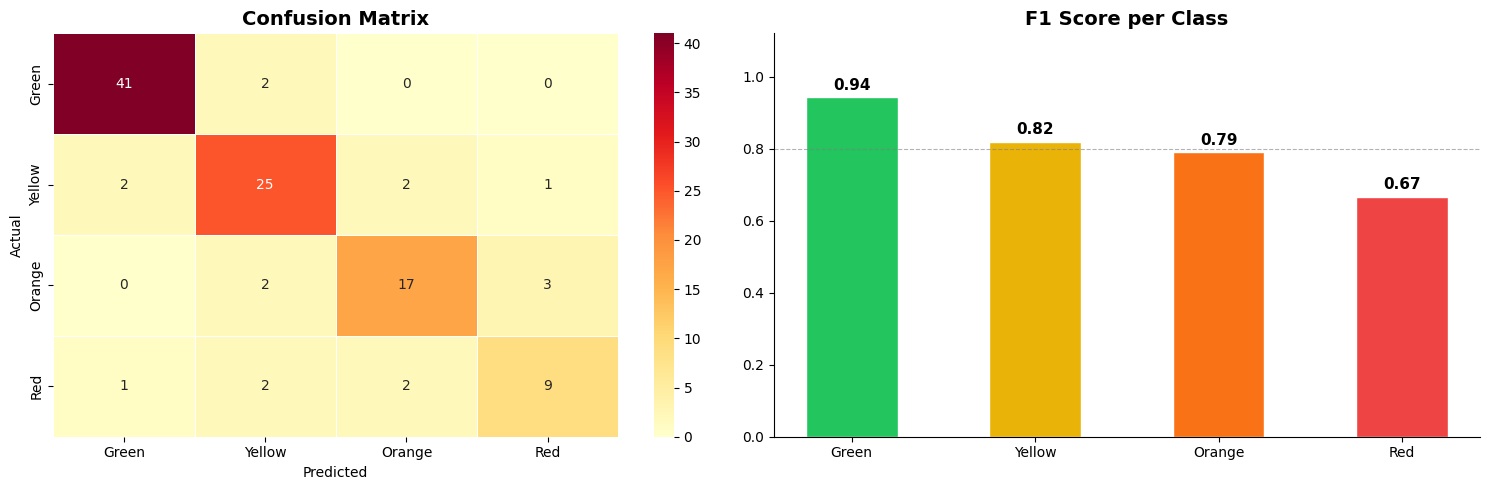

['food_classifier.pkl']

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
pipeline.fit(X_tr, y_tr)
y_pred = pipeline.predict(X_te)

print("=" * 55)
print("        CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_te, y_pred, zero_division=0, target_names=VALID_LABELS))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cm = confusion_matrix(y_te, y_pred, labels=VALID_LABELS)
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd',
            xticklabels=VALID_LABELS, yticklabels=VALID_LABELS,
            ax=axes[0], linewidths=0.5, linecolor='white')
axes[0].set_title('Confusion Matrix', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

f1_per = f1_score(y_te, y_pred, labels=VALID_LABELS, average=None, zero_division=0)
bars   = axes[1].bar(VALID_LABELS, f1_per,
                     color=[COLORS[l] for l in VALID_LABELS],
                     edgecolor='white', width=0.5)
axes[1].set_ylim(0, 1.12)
axes[1].axhline(0.8, color='grey', linestyle='--', linewidth=0.8, alpha=0.6)
axes[1].set_title('F1 Score per Class', fontsize=14, fontweight='bold')
for bar, val in zip(bars, f1_per):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.02, f'{val:.2f}',
                 ha='center', fontsize=11, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
plt.tight_layout(); plt.show()

# retrain on full data
pipeline.fit(X, y)
joblib.dump(pipeline, 'food_classifier.pkl')

In [ ]:
clf_model = joblib.load('food_classifier.pkl')

master_db = {}
for _, row in df.iterrows():
    master_db[row['ingredient_name']] = {
        'label'          : row['label'],
        'category'       : row['category'],
        'e_number'       : row['e_number'],
        'synonyms_india' : row['synonyms_india'],
    }
db_keys = list(master_db.keys())

with open('food_master_db.json', 'w') as f:
    json.dump(master_db, f, indent=2)

print(f" Master DB : {len(master_db)} ingredients")
print(f"   DB keys   : {len(db_keys)}")


 Master DB : 541 ingredients
   DB keys   : 541


In [ ]:
def classify_one(raw_name: str) -> dict:
    """
    Classify a single ingredient token using 4 stages:
      0. normalise()  — OCR fix + synonym resolution
      1. Exact match  — O(1) dict lookup
      2. Fuzzy match  — rapidfuzz ratio >= 82%
      3. ML model     — TF-IDF + Random Forest
    """
    original = str(raw_name).strip().lower()
    canon    = normalise(original)
    syn_note = f" [via '{original}']" if canon != original else ""

    # Stage 1
    if canon in master_db:
        info = master_db[canon]
        return {**info, 'confidence': 1.0,
                'method': f'exact{syn_note}'}

    # Stage 2
    hit = process.extractOne(canon, db_keys, scorer=fuzz.ratio)
    if hit and hit[1] >= 82:
        info = master_db[hit[0]]
        return {**info, 'confidence': hit[1] / 100,
                'method': f'fuzzy {hit[1]}% → {hit[0]}{syn_note}'}

    # Stage 3
    proba   = clf_model.predict_proba([canon])[0]
    classes = clf_model.classes_
    top_idx = int(np.argmax(proba))
    return {
        'label'          : classes[top_idx],
        'category'       : 'ML-predicted',
        'e_number'       : '',
        'synonyms_india' : '',
        'confidence'     : float(proba[top_idx]),
        'method'         : f'ml_model{syn_note}',
    }


def split_ingredients(raw_text: str) -> list:
    """Split a raw label text into individual ingredient tokens."""
    text = raw_text.lower()
    text = re.sub(
        r'(ingredients|contains|composition|ingr[eé]dients)\s*[:\-]?\s*',
        '', text, flags=re.IGNORECASE)
    chunks = re.split(r'[,;\n•\|/]+', text)
    cleaned = []
    for chunk in chunks:
        chunk = re.sub(r'\(.*?\)', ' ', chunk)
        chunk = re.sub(r'[^a-z0-9\s\-]', ' ', chunk)
        chunk = re.sub(r'\s+', ' ', chunk).strip()
        if chunk and len(chunk) >= 2:
            cleaned.append(chunk)
    return cleaned


def scan_ingredients(text: str) -> OrderedDict:
    results = OrderedDict()
    for token in split_ingredients(text):
        results[token] = classify_one(token)
    return results


def get_verdict(results: dict):
    counts = Counter(r['label'] for r in results.values())
    worst  = max(results.values(),
                 key=lambda r: VERDICT_WEIGHT.get(r['label'], 0))['label']
    if worst == 'Red':
        msg = '🔴 AVOID — Contains banned or high-risk ingredients'
    elif counts.get('Orange', 0) >= 3:
        msg = '🟠 CAUTION — Multiple preservatives present'
    elif worst == 'Orange':
        msg = '🟠 CAUTION — Contains notable preservatives'
    elif counts.get('Yellow', 0) >= 4:
        msg = '🟡 MODERATE — Several mildly processed ingredients'
    elif worst == 'Yellow':
        msg = '🟡 MOSTLY GOOD — Minor processed ingredients'
    else:
        msg = '🟢 CLEAN — All natural ingredients'
    return msg, counts


def print_report(results: dict):
    W = 82
    print('\n' + '═' * W)
    print('                🍽️  FOOD INGREDIENT SAFETY REPORT')
    print('═' * W)
    print(f"  {'INGREDIENT':<30} {'LABEL':<10} {'CONF':>5}  METHOD")
    print('─' * W)
    for name, info in results.items():
        em      = EMOJI.get(info['label'], '?')
        ename   = f" [{info['e_number']}]" if info['e_number'] else ''
        display = (name + ename)[:30]
        syns    = info.get('synonyms_india', '')
        print(f"  {display:<30} {em} {info['label']:<8} "
              f"{info['confidence']:>5.0%}  {info['method']}")
        if syns and 'exact' in info['method']:
            hints = ' | '.join(x.strip() for x in syns.split('|')[:2])
            if hints:
                print(f"  {'':30}   ↳ also known as: {hints[:55]}")
    verdict, counts = get_verdict(results)
    print('─' * W)
    print('  📊 BREAKDOWN :')
    for lbl in VALID_LABELS:
        n = counts.get(lbl, 0)
        if n:
            print(f'     {EMOJI[lbl]} {lbl:<8}: {n}')
    print('─' * W)
    print(f'  🏁 VERDICT   : {verdict}')
    print('═' * W + '\n')


print(" 4-stage classifier ready")


 4-stage classifier ready


In [ ]:
REVIEW_LOG_PATH = 'review_log.json'

def load_review_log():
    if os.path.exists(REVIEW_LOG_PATH):
        with open(REVIEW_LOG_PATH) as f:
            return json.load(f)
    return {}

def save_review_log(log):
    with open(REVIEW_LOG_PATH, 'w') as f:
        json.dump(log, f, indent=2)


def already_in_csv(canonical: str) -> bool:
    """Return True if canonical (or any synonym of it) already exists in df."""
    if canonical in master_db:
        return True
    for _, row in df.iterrows():
        existing_syns = [s.strip().lower()
                         for s in str(row['synonyms_india']).split('|')
                         if s.strip()]
        if canonical in existing_syns:
            return True
    return False


def append_to_csv(name: str, label: str, category: str,
                  e_number: str = '', synonyms_india: str = ''):
    """Append one row to CSV and refresh all in-memory structures."""
    global df, master_db, db_keys, synonym_index

    new_row = pd.DataFrame([{
        'ingredient_name': name,
        'e_number'       : e_number,
        'category'       : category,
        'label'          : label,
        'synonyms_india' : synonyms_india,
    }])
    df = pd.concat([df, new_row], ignore_index=True)
    df.to_csv(CSV_PATH, index=False)

    master_db[name] = {
        'label': label, 'category': category,
        'e_number': e_number, 'synonyms_india': synonyms_india,
    }
    db_keys = list(master_db.keys())
    synonym_index[name] = name
    if e_number:
        synonym_index[e_number.lower()] = name
    for alias in synonyms_india.split('|'):
        alias = alias.strip().lower()
        if alias and len(alias) >= 2:
            synonym_index[alias] = name


def retrain():
    """Retrain model on current df and return (cv_accuracy, total_rows)."""
    global clf_model
    df['feature_text'] = df.apply(make_feature, axis=1)
    X_new = df['feature_text'].tolist()
    y_new = df['label'].tolist()
    min_class = min(Counter(y_new).values())
    n_splits  = min(3, min_class)
    if n_splits < 2:
        clf_model.fit(X_new, y_new)
        joblib.dump(clf_model, 'food_classifier.pkl')
        return None, len(X_new)
    cv_scores = cross_val_score(
        clf_model, X_new, y_new,
        cv=StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42),
        scoring='accuracy')
    clf_model.fit(X_new, y_new)
    joblib.dump(clf_model, 'food_classifier.pkl')
    return cv_scores.mean(), len(X_new)


def auto_learn(results: dict,
               high_conf: float = 0.80,
               low_conf:  float = 0.60) -> tuple:
    """
    Process scan results and write confident new ingredients to CSV.

    - confidence >= high_conf  →  append to CSV + retrain immediately
    - confidence >= low_conf   →  save to review_log.json
    - below low_conf           →  discard
    - already in CSV           →  skip silently

    Returns (added, flagged).
    """
    review_log = load_review_log()
    added, flagged, new_rows = 0, 0, []

    for raw_name, info in results.items():
        if not info['method'].startswith('ml_model'):
            continue   # already known via exact or fuzzy

        canonical = normalise(raw_name)
        conf      = info['confidence']

        if already_in_csv(canonical):
            continue

        if conf >= high_conf:
            append_to_csv(
                name     = canonical,
                label    = info['label'],
                category = 'auto-learned',
                e_number = info.get('e_number', ''),
            )
            new_rows.append(canonical)
            added += 1
            print(f" Auto-added  [{info['label']:6}] '{canonical}'  "
                  f"conf {conf:.0%}")

        elif conf >= low_conf:
            review_log[canonical] = {
                'predicted_label': info['label'],
                'confidence'     : round(conf, 3),
                'correct_label'  : None,
            }
            flagged += 1
            print(f"  🔍 Flagged     [{info['label']:6}] '{canonical}'  "
                  f"conf {conf:.0%}")

    if new_rows:
        acc, total = retrain()
        acc_str = f"{acc:.3f}" if acc else "—"
        print(f"  🔄 Retrained on {total} rows | CV Accuracy: {acc_str}")

    save_review_log(review_log)

    if added == 0 and flagged == 0:
        print("  ℹ️  No new ingredients — everything already in the database.")

    return added, flagged


def apply_corrections():
    """
    Apply manual label corrections from review_log.json.
    Open the file, set 'correct_label' for wrong predictions, then run this.
    """
    review_log = load_review_log()
    fixed = 0
    for name, info in review_log.items():
        correct = info.get('correct_label')
        if correct and correct in VALID_LABELS and not already_in_csv(name):
            append_to_csv(name=name, label=correct,
                          category='manually-corrected')
            fixed += 1
            print(f"  Corrected '{name}' → {correct}")
    if fixed:
        acc, total = retrain()
        acc_str = f"{acc:.3f}" if acc else "—"
        print(f"  🔄 Retrained on {total} rows | CV Accuracy: {acc_str}")
    else:
        print("Nothing to apply.")
        print(f"Edit '{REVIEW_LOG_PATH}' — set 'correct_label' for wrong entries.")
    save_review_log(review_log)


print(" CSV write-back + auto-learn engine ready")
print(f"   CSV           : {CSV_PATH}")
print(f"   Review log    : {REVIEW_LOG_PATH}")
print(f"   Auto-add threshold  : conf >= 0.80")
print(f"   Flag threshold      : conf >= 0.60")


 CSV write-back + auto-learn engine ready
   CSV           : /content/ingredient_dataset_with_synonyms (1).csv
   Review log    : review_log.json
   Auto-add threshold  : conf >= 0.80
   Flag threshold      : conf >= 0.60


In [ ]:
def preprocess_image(image_path: str, debug: bool = False):
    """OpenCV pre-processing pipeline → PIL Image ready for Tesseract."""
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"Cannot open: {image_path}")

    h, w = img.shape[:2]
    if w < 1000:
        scale = 1000 / w
        img   = cv2.resize(img, None, fx=scale, fy=scale,
                           interpolation=cv2.INTER_CUBIC)
        print(f"  ↳ Upscaled {w}×{h} → {img.shape[1]}×{img.shape[0]}")

    grey     = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    denoised = cv2.fastNlMeansDenoising(
        grey, h=10, templateWindowSize=7, searchWindowSize=21)
    binary   = cv2.adaptiveThreshold(
        denoised, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=31, C=10)
    kernel  = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

    coords = np.column_stack(np.where(cleaned < 128))
    if len(coords) > 50:
        angle = cv2.minAreaRect(coords)[-1]
        if angle < -45: angle = 90 + angle
        if abs(angle) > 0.5:
            M = cv2.getRotationMatrix2D(
                (cleaned.shape[1]//2, cleaned.shape[0]//2), angle, 1.0)
            cleaned = cv2.warpAffine(
                cleaned, M, (cleaned.shape[1], cleaned.shape[0]),
                flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
            print(f"  ↳ Deskewed {angle:.1f}°")

    if debug:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4))
        axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[0].set_title('Original')
        axes[1].imshow(grey,    cmap='gray'); axes[1].set_title('Greyscale')
        axes[2].imshow(cleaned, cmap='gray'); axes[2].set_title('Binarised + Deskewed')
        for ax in axes: ax.axis('off')
        plt.tight_layout(); plt.show()

    return Image.fromarray(cleaned)


def ocr_scan(image_path: str,
             debug: bool = False,
             learn: bool = True) -> tuple:
    """
    Full pipeline: image → OCR → classify → auto_learn.

    Args:
        image_path : path to product label photo
        debug      : show OpenCV pre-processing steps
        learn      : run auto_learn() on results (writes to CSV if confident)

    Returns:
        (raw_ocr_text, results_dict)
    """
    print(f"📷 Image: {image_path}")
    pil_img   = preprocess_image(image_path, debug=debug)
    text_psm6 = pytesseract.image_to_string(
        pil_img, config='--oem 3 --psm 6 -l eng')
    text_psm3 = pytesseract.image_to_string(
        pil_img, config='--oem 3 --psm 3 -l eng')
    raw_text  = text_psm6 if len(text_psm6) >= len(text_psm3) else text_psm3

    if not raw_text.strip():
        print("  OCR returned no text — try a clearer / closer photo.")
        return '', {}

    print(f"\n Raw OCR ({len(raw_text)} chars):")
    print("─" * 65)
    print(raw_text[:700])
    if len(raw_text) > 700:
        print(f"… ({len(raw_text) - 700} more chars)")
    print("─" * 65)

    results = scan_ingredients(raw_text)
    if not results:
        print(" No ingredient tokens found.")
        print("    Tip: crop image to just the ingredient section.")
        return raw_text, {}

    print_report(results)

    if learn:
        print("🔄 Auto-learning from OCR results…")
        added, flagged = auto_learn(results)
        print(f"   Added to CSV: {added}  |  Flagged for review: {flagged}")

    return raw_text, results


def ocr_scan_enhanced(image_path: str,
                      contrast:  float = 2.0,
                      sharpness: float = 2.0,
                      debug:     bool  = False,
                      learn:     bool  = True) -> tuple:
    """
    PIL contrast + sharpness boost before binarisation.
    Use when default OCR misses text on bright / glossy packaging.
    Tune contrast (1.5–3.0) and sharpness (1.5–4.0).
    """
    img = Image.open(image_path).convert('RGB')
    if img.width < 1000:
        ratio = 1000 / img.width
        img   = img.resize((1000, int(img.height * ratio)), Image.LANCZOS)
    img  = ImageEnhance.Contrast(img).enhance(contrast)
    img  = ImageEnhance.Sharpness(img).enhance(sharpness)
    grey = img.convert('L').filter(ImageFilter.GaussianBlur(radius=0.5))
    arr    = np.array(grey)
    binary = cv2.adaptiveThreshold(
        arr, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY, blockSize=25, C=8)
    pil_bin = Image.fromarray(binary)

    if debug:
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        ax[0].imshow(img)
        ax[0].set_title(f'Enhanced  contrast={contrast}  sharpness={sharpness}')
        ax[1].imshow(pil_bin, cmap='gray'); ax[1].set_title('Binarised')
        for a in ax: a.axis('off')
        plt.tight_layout(); plt.show()

    raw_text = pytesseract.image_to_string(pil_bin, config='--oem 3 --psm 6 -l eng')
    if not raw_text.strip():
        raw_text = pytesseract.image_to_string(pil_bin, config='--oem 3 --psm 3 -l eng')

    print(f" Enhanced OCR ({len(raw_text)} chars):")
    print(raw_text[:600])

    results = scan_ingredients(raw_text)
    if results:
        print_report(results)
        if learn:
            added, flagged = auto_learn(results)
            print(f"   Added to CSV: {added}  |  Flagged: {flagged}")
    else:
        print("  No ingredients found. Adjust contrast/sharpness or crop the label.")

    return raw_text, results

📤 Please upload a product label image:


Saving Screenshot 2026-05-15 222041.png to Screenshot 2026-05-15 222041.png
Selected Image: Screenshot 2026-05-15 222041.png
📷 Image: Screenshot 2026-05-15 222041.png
  ↳ Upscaled 352×84 → 1000×239
  ↳ Deskewed -1.7°


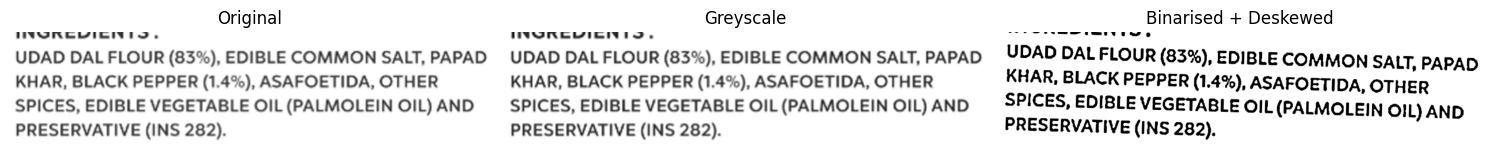


 Raw OCR (182 chars):
─────────────────────────────────────────────────────────────────
ol eonaese ee

UDAD DAL FLOUR (83%), EDIBLE COMMON SALT, PAPAD
KHAR, BLACK PEPPER (1.4%), ASAFOETIDA, OTHER
SPICES, EDIBLE VEGETABLE OIL (PALMOLEIN OIL) AND
PRESERVATIVE (INS 282).

─────────────────────────────────────────────────────────────────

══════════════════════════════════════════════════════════════════════════════════
                🍽️  FOOD INGREDIENT SAFETY REPORT
══════════════════════════════════════════════════════════════════════════════════
  INGREDIENT                     LABEL       CONF  METHOD
──────────────────────────────────────────────────────────────────────────────────
  ol eonaese ee                  🟡 Yellow     51%  ml_model
  udad dal flour                 🟢 Green      48%  ml_model
  edible common salt             🟢 Green     100%  exact [via 'edible common salt']
                                   ↳ also known as: Namak | Noon
  papad                          🟡 

In [ ]:
from google.colab import files
import os

print("Please upload a product label image:")
uploaded = files.upload()

if len(uploaded) == 0:
    print("No file uploaded.")
else:
    IMAGE_PATH = list(uploaded.keys())[0]
    print(f"Selected Image: {IMAGE_PATH}")

    DEBUG = True

    if os.path.exists(IMAGE_PATH):
        raw_text, ocr_results = ocr_scan(IMAGE_PATH, debug=DEBUG, learn=True)
    else:
        print(f"File not found: {IMAGE_PATH}")

In [ ]:
INGREDIENT_TEXT = """
 Potato Flakes, Edible
Vegetable Oil (Palmolein Oil), Gram
Flour, Tepary Beans Flour *Spices and
Condiments (Coriander Powder, Cumin
Powder, Red Chilli Powder, Black
Pepper Powder, Turmeric Powder, Ginger
Powder, Big Cardamom Powder, Clove
Powder, Onion Powder, Garlic Powder &
Spices Extract), Edible Common Salt,
Starch Powder, Sugar Powder, Maltodextrin,
Dextrose, Milk Solids, Acidity Regulators
(INS 330 & 296) and Flavour Enhancers
(INS 627 & INS 631).
"""

# Show synonym resolution before classifying
print("── Synonym resolution ──────────────────────────────────────────────")
for token in split_ingredients(INGREDIENT_TEXT):
    resolved = normalise(token)
    if resolved != token:
        print(f"  '{token}'" + " " * max(1, 22 - len(token)) + f"→  '{resolved}'")
print()

results = scan_ingredients(INGREDIENT_TEXT)
print_report(results)

print("🔄 Auto-learning from manual scan…")
added, flagged = auto_learn(results)
print(f"   Added to CSV: {added}  |  Flagged for review: {flagged}")


── Synonym resolution ──────────────────────────────────────────────
  'potato flakes'         →  'potato'
  'tepary beans flour spices and' →  'spices'
  'condiments coriander powder' →  'coriander'
  'red chilli powder'     →  'red chilli'
  'turmeric powder'       →  'turmeric'
  'big cardamom powder'   →  'cardamom'
  'onion powder'          →  'onion'
  'garlic powder'         →  'garlic'
  'spices extract'        →  'spices'
  'edible common salt'    →  'salt'
  'sugar powder'          →  'sugar'
  'milk solids'           →  'milk'


══════════════════════════════════════════════════════════════════════════════════
                🍽️  FOOD INGREDIENT SAFETY REPORT
══════════════════════════════════════════════════════════════════════════════════
  INGREDIENT                     LABEL       CONF  METHOD
──────────────────────────────────────────────────────────────────────────────────
  potato flakes                  🟢 Green     100%  exact [via 'potato flakes']
                  

In [ ]:
review_log = load_review_log()
if review_log:
    print(f" {len(review_log)} item(s) pending review:")
    print(f"  {'Ingredient':<35} {'Predicted':>10}  {'Conf':>5}  Correct")
    print("  " + "─" * 65)
    for name, info in review_log.items():
        correct = info.get('correct_label') or '— not set —'
        print(f"  {name:<35} {info['predicted_label']:>10}  "
              f"{info['confidence']:>5.0%}  {correct}")
    print(f"\nEdit '{REVIEW_LOG_PATH}' then run apply_corrections() below.")
else:
    print(" Review log empty — nothing pending.")


 6 item(s) pending review:
  Ingredient                           Predicted   Conf  Correct
  ─────────────────────────────────────────────────────────────────
  hydrolyzed peanut                        Green    74%  Set
  wheat gluten                             Green    60%  Set
  maida                                    Green    60%  Set
  wheat power                              Green    73%  Set
  antioxidant                             Yellow    66%  Set
  gram                                     Green    68%  Set

Edit 'review_log.json' then run apply_corrections() below.


In [ ]:
# Run after editing review_log.json
apply_corrections()


Nothing to apply.
Edit 'review_log.json' — set 'correct_label' for wrong entries.


In [ ]:
def add_synonym(ingredient_name: str, new_alias: str):
    """
    Add new_alias to the synonyms_india column of ingredient_name.
    Updates CSV + in-memory synonym_index + master_db.

    Example:
        add_synonym('jaggery', 'nolen gur')
        add_synonym('turmeric', 'pasupu')
        add_synonym('monosodium glutamate', 'chinese namak')
    """
    global df, master_db, synonym_index

    canon = ingredient_name.strip().lower()
    alias = new_alias.strip().lower()

    if canon not in master_db:
        print(f" '{canon}' not in database.")
        return

    mask     = df['ingredient_name'] == canon
    existing = df.loc[mask, 'synonyms_india'].values[0]
    ex_list  = [s.strip().lower()
                for s in str(existing).split('|') if s.strip()]

    if alias in ex_list:
        print(f" '{alias}' already listed for '{canon}'.")
        return

    ex_list.append(alias)
    new_syns = ' | '.join(ex_list)

    df.loc[mask, 'synonyms_india'] = new_syns
    df.to_csv(CSV_PATH, index=False)

    master_db[canon]['synonyms_india'] = new_syns
    synonym_index[alias] = canon

    print(f"✅ '{alias}'  →  '{canon}'")
    print(f"   Updated synonyms_india: {new_syns[:100]}")


# ── Examples ──────────────────────────────────────────────────────────────────
# add_synonym('jaggery',              'nolen gur')
# add_synonym('turmeric',             'pasupu')
# add_synonym('monosodium glutamate', 'chinese namak')
# add_synonym('chickpea flour',       'harbhara pith')


In [ ]:
def synonym_coverage_report():
    covered   = df[df['synonyms_india'] != '']
    uncovered = df[df['synonyms_india'] == '']

    print(f"Coverage : {len(covered)}/{len(df)} ingredients have Indian synonyms")
    alias_counts = (covered['synonyms_india']
                    .str.split('|')
                    .apply(lambda x: len([s for s in x if s.strip()])))
    print(f"Avg aliases per covered ingredient : {alias_counts.mean():.1f}")
    print(f"Max aliases                        : {alias_counts.max()}")
    print()

    print("Top 10 by alias count:")
    top = covered.copy()
    top['n'] = alias_counts.values
    top = top.nlargest(10, 'n')
    for _, row in top.iterrows():
        em = EMOJI[row['label']]
        print(f"  {em} {row['ingredient_name']:<30}  ({row['n']} aliases)")
        print(f"     {row['synonyms_india'][:80]}")
    print()

    print(f"Without Indian synonym ({len(uncovered)}) — sample:")
    for name in uncovered['ingredient_name'].head(12).tolist():
        print(f"  · {name}")
    if len(uncovered) > 12:
        print(f"  … and {len(uncovered)-12} more (mostly technical chemical names)")

synonym_coverage_report()


Coverage : 340/543 ingredients have Indian synonyms
Avg aliases per covered ingredient : 4.6
Max aliases                        : 8

Top 10 by alias count:
  🟢 jaggery                         (8 aliases)
     Gur | Gud | Vellam | Bella | Bellam | Gul | Nolen gur | Khandsari
  🟢 wheat flour                     (8 aliases)
     Atta | Gehun atta | Godhuma pindi | Godhumai maavu | Godi hittu | Godhuma | Maid
  🟢 semolina                        (8 aliases)
     Suji | Rava | Sooji | Rawa | Semiya rava | Sajji | Bombay rava | Chiroti rava
  🟢 curd                            (8 aliases)
     Dahi | Doi | Thayir | Perugu | Mosaru | Moru | Tak | Dadhi
  🟢 buttermilk                      (8 aliases)
     Chaach | Chhaas | Mor | Majjiga | Majjige | Moru | Taak | Lassi
  🟢 red chilli                      (8 aliases)
     Lal mirch | Lal mirchi | Lal mircha | Milagai | Endu mirapa | Kempu menasinkai |
  🟢 chickpeas                       (8 aliases)
     Chana | Kabuli chana | Chole | Kondakadalai 

In [ ]:
from google.colab import files

print(f"CSV rows       : {len(df)}")
print(f"Master DB      : {len(master_db)} ingredients")
print(f"Synonym aliases: {len(synonym_index)}")
print()

for fname in [CSV_PATH, 'food_classifier.pkl',
              'food_master_db.json', REVIEW_LOG_PATH]:
    if os.path.exists(fname):
        files.download(fname)
        size = os.path.getsize(fname)
        print(f"{fname}  ({size:,} bytes)")
    else:
        print(f"{fname}  (not created yet)")


CSV rows       : 543
Master DB      : 543 ingredients
Synonym aliases: 2148



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/content/ingredient_dataset_with_synonyms (1).csv  (49,606 bytes)


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

food_master_db.json  (84,821 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

review_log.json  (639 bytes)
